# Spring Force Field Exact Line-Search Experiment

This notebook tests the new `ExactLineSearchDirectionalImplicitMultipleSystemOptimizer` on a spring force field (`SpringFF`). It uses exact line minimization along the steepest force direction and compares learned spring parameters to target values.

In [1]:
import sys
import os
sys.path.append(os.path.abspath(os.path.join(os.getcwd(), '..', '..')))

import copy
import torch
import numpy as np
import matplotlib.pyplot as plt

from geomatry.opt_Energy_approximated.optimizer import ExactLineSearchDirectionalImplicitMultipleSystemOptimizer
from geomatry.opt.loss import rmsd_loss
from geomatry.ff.graph import get_given_graph_builder
from geomatry.ff.springs import SpringFF, _random_spring_systems, _random_spring_ff_param

In [2]:
# Experiment configuration
systemN = 30
N = 16
N_pairs = 40
max_Za = 5
fixed_atom_indices = [0, 1]

# Generate random spring systems and target parameters
Ras, Zas, idx_is, idx_js = _random_spring_systems(systemN, N, N_pairs, max_Za, start_Za=1)
k, r0 = _random_spring_ff_param(max_Za, r0_max=10, k_max=10)

ff = SpringFF(max_Za)
ff.reset_parameters(k, r0)
params_star = copy.deepcopy(ff.state_dict())

graph_builders = [get_given_graph_builder(idx_i, idx_j) for idx_i, idx_j in zip(idx_is, idx_js)]

print('target k mean', params_star['k'][1:, 1:].mean().item())
print('target r0 mean', params_star['r0'][1:, 1:].mean().item())

target k mean 5.524074717087205
target r0 mean 5.356804755848026


In [3]:
optimizer = ExactLineSearchDirectionalImplicitMultipleSystemOptimizer(
    Ras, Zas, graph_builders, ff, rmsd_loss,
    params_star=params_star,
    fixed_atom_indices=fixed_atom_indices,
    fmax=1e-5
)

/Users/soonhyun/Desktop/CollaborationWithWeiliang/GeometryOptimize/GeoMatry/geomatry/ff/utils.py:33: UserWarning: Using a non-tuple sequence for multidimensional indexing is deprecated and will be changed in pytorch 2.9; use x[tuple(seq)] instead of x[seq]. In pytorch 2.9 this will be interpreted as tensor index, x[torch.tensor(seq)], which will result either in an error or a different result (Triggered internally at /Users/runner/work/pytorch/pytorch/pytorch/torch/csrc/autograd/python_variable_indexing.cpp:353.)
  output = params[indices]    # (num_samples, ...)


In [4]:
# Perturb the spring parameters before optimization
perturbed_k = torch.abs(k.clone() + 2.5 * torch.randn_like(k))
perturbed_r0 = torch.abs(r0.clone() + 1.2 * torch.randn_like(r0))
ff.reset_parameters(perturbed_k, perturbed_r0)
params_0 = copy.deepcopy(ff.state_dict())

print('start k mean', params_0['k'][1:, 1:].mean().item())
print('start r0 mean', params_0['r0'][1:, 1:].mean().item())

start k mean 5.627243441434527
start r0 mean 5.416557188298306


In [5]:
new_params = optimizer.optimize(params_0, epoch=30001, print_period=5000, e_size=0.5, eN=11, sg=2)
print('optimization complete')

  0%|          | 0/30001 [00:00<?, ?it/s]/Users/soonhyun/Desktop/CollaborationWithWeiliang/GeometryOptimize/GeoMatry/geomatry/ff/utils.py:33: UserWarning: Using a non-tuple sequence for multidimensional indexing is deprecated and will be changed in pytorch 2.9; use x[tuple(seq)] instead of x[seq]. In pytorch 2.9 this will be interpreted as tensor index, x[torch.tensor(seq)], which will result either in an error or a different result (Triggered internally at /Users/runner/work/pytorch/pytorch/pytorch/torch/csrc/autograd/python_variable_indexing.cpp:353.)
  output = params[indices]    # (num_samples, ...)
  0%|          | 7/30001 [00:00<15:32, 32.16it/s, alpha_star=2.9942e-01, min_epsilon=N/A, total_scale=2.376902e-02]

Iteration 0, alpha_star=2.9942e-01, total_scale=2.435076e-02


 17%|█▋        | 5004/30001 [02:34<15:29, 26.90it/s, alpha_star=1.8574e-01, min_epsilon=N/A, total_scale=1.126448e-02]

Iteration 5000, alpha_star=4.6782e-02, total_scale=6.255860e-03


 33%|███▎      | 10006/30001 [16:45<09:46, 34.07it/s, alpha_star=1.0469e-02, min_epsilon=N/A, total_scale=2.149977e-03]   

...

Iteration 20000, alpha_star=3.9234e-04, total_scale=3.300956e-05


 83%|████████▎ | 25006/30001 [28:28<02:43, 30.54it/s, alpha_star=5.9835e-04, min_epsilon=N/A, total_scale=3.106165e-05]

Iteration 25000, alpha_star=6.3482e-04, total_scale=5.872678e-05


100%|██████████| 30001/30001 [31:25<00:00, 15.91it/s, alpha_star=3.9234e-04, min_epsilon=N/A, total_scale=2.056185e-05]

Iteration 30000, alpha_star=3.9234e-04, total_scale=2.056185e-05
optimization complete


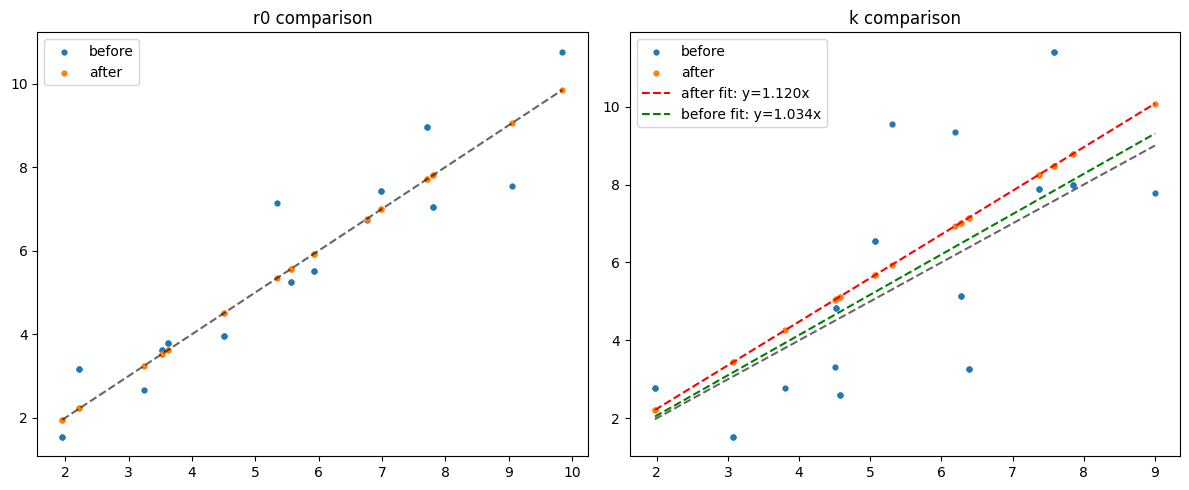

In [10]:
# Compare before and after optimization for k and r0
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
target_r0 = params_star['r0'][1:, 1:].detach().reshape(-1).cpu().numpy()
before_r0 = params_0['r0'][1:, 1:].detach().reshape(-1).cpu().numpy()
after_r0 = new_params['r0'][1:, 1:].detach().reshape(-1).cpu().numpy()
plt.scatter(target_r0, before_r0, label='before', s=12)
plt.scatter(target_r0, after_r0, label='after', s=12)
plt.plot([target_r0.min(), target_r0.max()], [target_r0.min(), target_r0.max()], 'k--', alpha=0.6)
plt.title('r0 comparison')
plt.legend()

plt.subplot(1, 2, 2)
target_k = params_star['k'][1:, 1:].detach().reshape(-1).cpu().numpy()
before_k = params_0['k'][1:, 1:].detach().reshape(-1).cpu().numpy()
after_k = new_params['k'][1:, 1:].detach().reshape(-1).cpu().numpy()
plt.scatter(target_k, before_k, label='before', s=12)
plt.scatter(target_k, after_k, label='after', s=12)

# Fit proportional relations for k
slope_before_k = (target_k * before_k).sum() / (target_k * target_k).sum()
slope_after_k = (target_k * after_k).sum() / (target_k * target_k).sum()
line_x_k = np.array([target_k.min(), target_k.max()])
plt.plot(line_x_k, slope_after_k * line_x_k, 'r--', label=f'after fit: y={slope_after_k:.3f}x')
plt.plot(line_x_k, slope_before_k * line_x_k, 'g--', label=f'before fit: y={slope_before_k:.3f}x')

plt.plot([target_k.min(), target_k.max()], [target_k.min(), target_k.max()], 'k--', alpha=0.6)
plt.title('k comparison')
plt.legend()

plt.tight_layout()
plt.show()